In [1]:
# importing packages
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import scipy as sp
import seaborn as sn
import warnings
warnings.simplefilter("ignore")

I'm curious how the minimum variance and maximum Sharpe ratio portfolios (discussed in 00_efficient_frontier) move over time. By using the same approach, I would like to investigate this.

In [2]:
symbols = ['XDWT.DE', 'XDWI.DE', 'XDW0.DE', 'XDWH.DE', 'XDWF.DE', 'XDWC.DE', 'XWTS.DE', 'XDWS.DE'] # Sector ETFs from Xtrackers
n = len(symbols)
for symbol in symbols:
    info = yf.Ticker(symbol).info
    print(f"{symbol}: {info.get('longName', 'N/A')}")

datasets = {}
years = [2024, 2023, 2022, 2021, 2020, 2019, 2018]
for year in years:
    raw_data = yf.download(symbols, start = f'{year}-01-01')
    data = raw_data['Close']
    datasets[year] = data

XDWT.DE: Xtrackers MSCI World Information Technology UCITS ETF 1C
XDWI.DE: Xtrackers MSCI World Industrials UCITS ETF 1C
XDW0.DE: Xtrackers MSCI World Energy UCITS ETF 1C
XDWH.DE: Xtrackers MSCI World Health Care UCITS ETF 1C
XDWF.DE: Xtrackers MSCI World Financials UCITS ETF 1C
XDWC.DE: Xtrackers MSCI World Consumer Discretionary UCITS ETF 1C
XWTS.DE: Xtrackers MSCI World Communication Services UCITS ETF 1C


[                       0%                       ]

XDWS.DE: Xtrackers MSCI World Consumer Staples UCITS ETF 1C


[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  8 of 8 completed
[*********************100%***********************]  8 of 8 completed


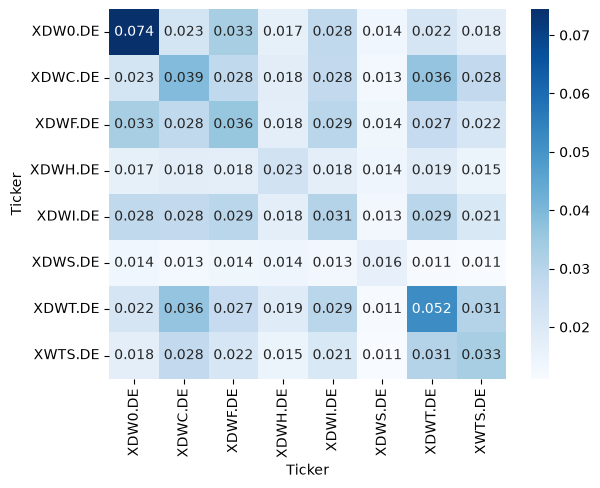

In [3]:
returns = {year: df.pct_change().dropna() for year, df in datasets.items()}
cov_matrix = {year: df.cov() * 252 for year, df in returns.items()} # Annualised
mean_returns = {year: df.mean() * 252 for year, df in returns.items()} # Annualised

sn.heatmap(cov_matrix[2018], annot=True, fmt='.3f', cmap='Blues')
plt.show()

In [4]:
random_weights = np.random.dirichlet(np.ones(n), size=500000).T # Dirichlet distribution to ensure weights sum to 1, while being random.

portfolio_returns = {year: random_weights.T @ mean_returns[year] for year, df in datasets.items()}
portfolio_variance = {year: np.einsum('ij,jk,ik->i', random_weights.T, cov_matrix[year], random_weights.T) for year, df in datasets.items()} # einsum for computation speed
portfolio_volatility = {year: np.sqrt(var) for year, var in portfolio_variance.items()}

In [5]:
rf = 0.0225 # ECB rate

wmv = {year: sp.optimize.minimize(lambda w: w.T @ cov_matrix[year] @ w, x0 = np.ones(n) / n, bounds=[(0, 1)] * n, constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) for year in datasets}
wms = {year: sp.optimize.minimize(lambda w: -w.T @ (mean_returns[year] - rf) / (np.sqrt(w.T @ cov_matrix[year] @ w)), x0 = np.ones(n) / n, bounds=[(0, 1)] * n, constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) for year in datasets}

wmv_return = {year: wmv[year].x.T @ mean_returns[year] for year in datasets}
wmv_volatility = {year: np.sqrt(wmv[year].x.T @ cov_matrix[year] @ wmv[year].x) for year in datasets}
wms_return = {year: wms[year].x.T @ mean_returns[year] for year in datasets}
wms_volatility = {year: np.sqrt(wms[year].x.T @ cov_matrix[year] @ wms[year].x) for year in datasets}

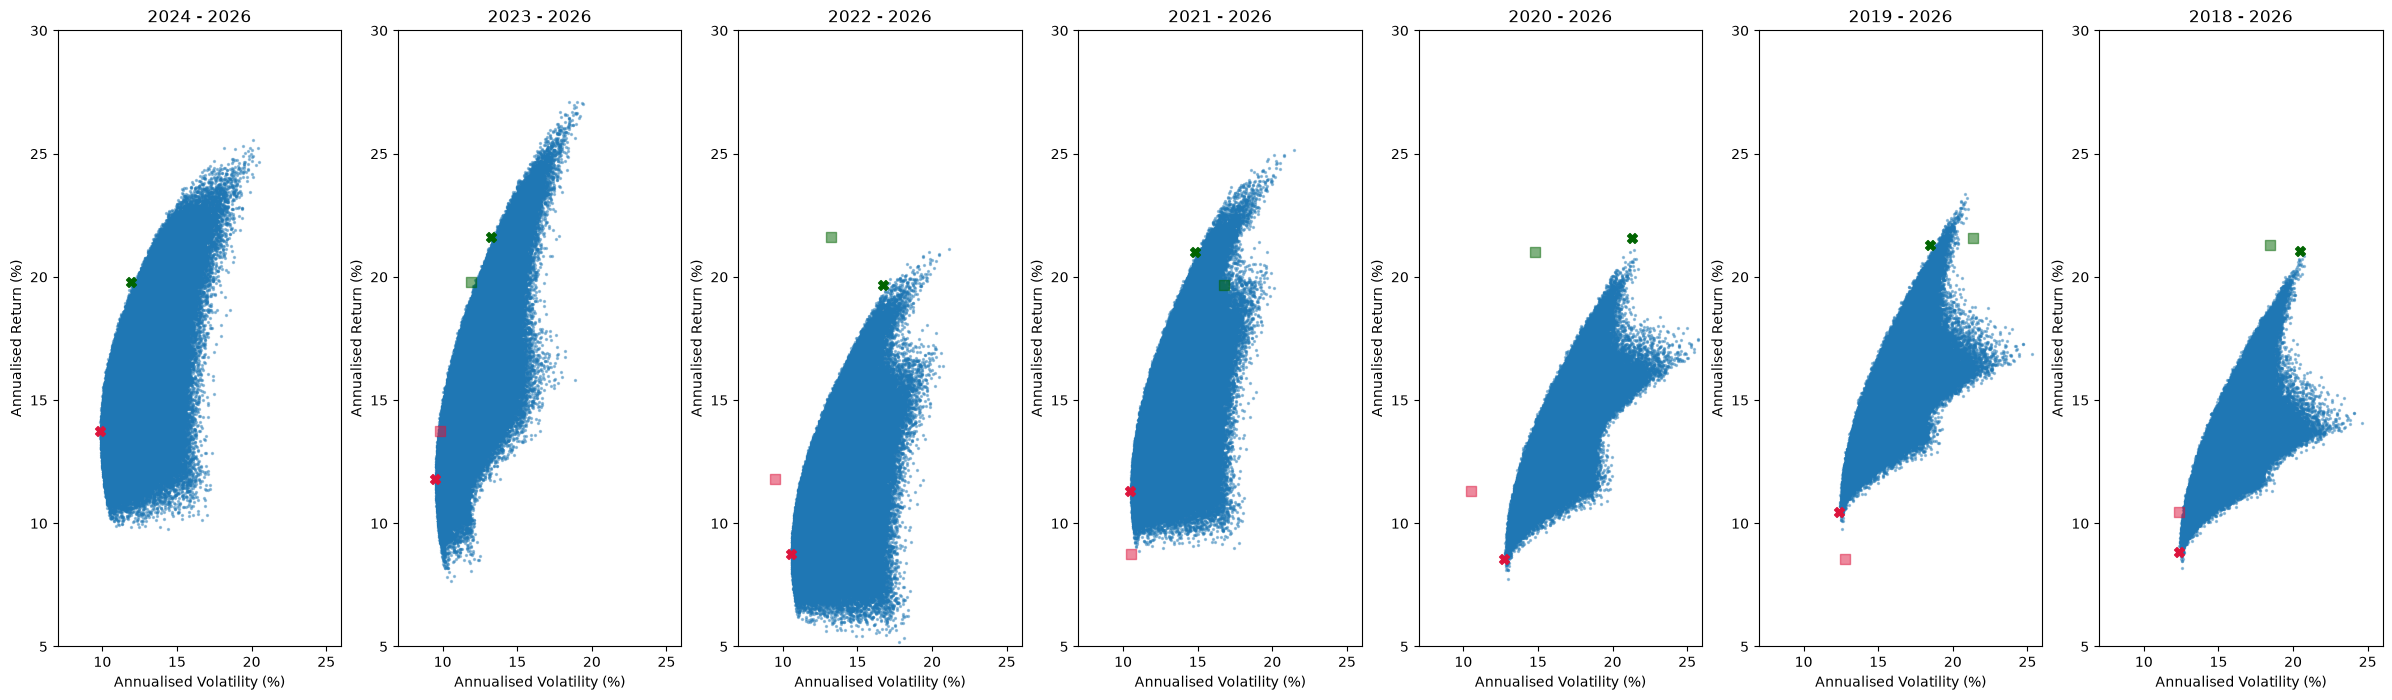

In [ ]:
plt.figure(figsize=(30, 8)) ### change to make weights instead of location of portfolios

for i, year in enumerate(datasets, start = 1):
    plt.subplot(1, 7, i)
    plt.scatter(portfolio_volatility[year] * 100, portfolio_returns[year] * 100, s=2, alpha=0.4)
    plt.scatter(wmv_volatility[year] * 100, wmv_return[year] * 100, s=50, c='crimson', marker='X', label='Minimum Variance Portfolio')
    plt.scatter(wms_volatility[year] * 100, wms_return[year] * 100, s=50, c='darkgreen', marker='X', label='Maximum Sharpe Ratio Portfolio')
    if year + 1 in datasets:
        plt.scatter(wmv_volatility[year + 1] * 100, wmv_return[year + 1] * 100, s=50, alpha=0.5, c='crimson', marker='s', label='Minimum Variance Portfolio')
        plt.scatter(wms_volatility[year + 1] * 100, wms_return[year + 1] * 100, s=50, alpha=0.5, c='darkgreen', marker='s', label='Maximum Sharpe Ratio Portfolio')
    plt.xlim(7, 26)
    plt.ylim(5, 30)
    plt.xlabel('Annualised Volatility (%)')
    plt.ylabel('Annualised Return (%)')
    plt.title(f'{year} - 2026')

plt.savefig('../images/01_0.png', dpi=200, bbox_inches='tight')
plt.show()

It's quite interesting to notice 

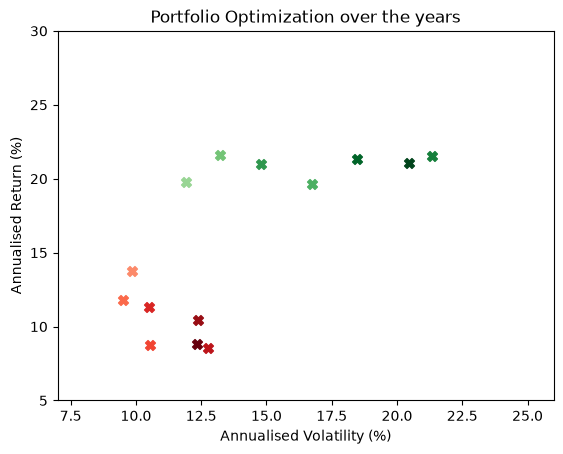

In [9]:
cmap_mv = plt.cm.Reds
cmap_ms = plt.cm.Greens
shades = np.linspace(0.4, 1.0, len(datasets))

for shade, year in zip(shades, datasets):
    plt.scatter(wmv_volatility[year] * 100, wmv_return[year] * 100, s=50, c=cmap_mv(shade), marker='X', label='Minimum Variance Portfolio')
    plt.scatter(wms_volatility[year] * 100, wms_return[year] * 100, s=50, c=cmap_ms(shade), marker='X', label='Maximum Sharpe Ratio Portfolio')
    plt.xlim(7, 26)
    plt.ylim(5, 30)
    plt.xlabel('Annualised Volatility (%)')
    plt.ylabel('Annualised Return (%)')
    plt.title(f'Portfolio Optimization over the years')

plt.savefig('../images/01_1.png', dpi=200, bbox_inches='tight')
plt.show()

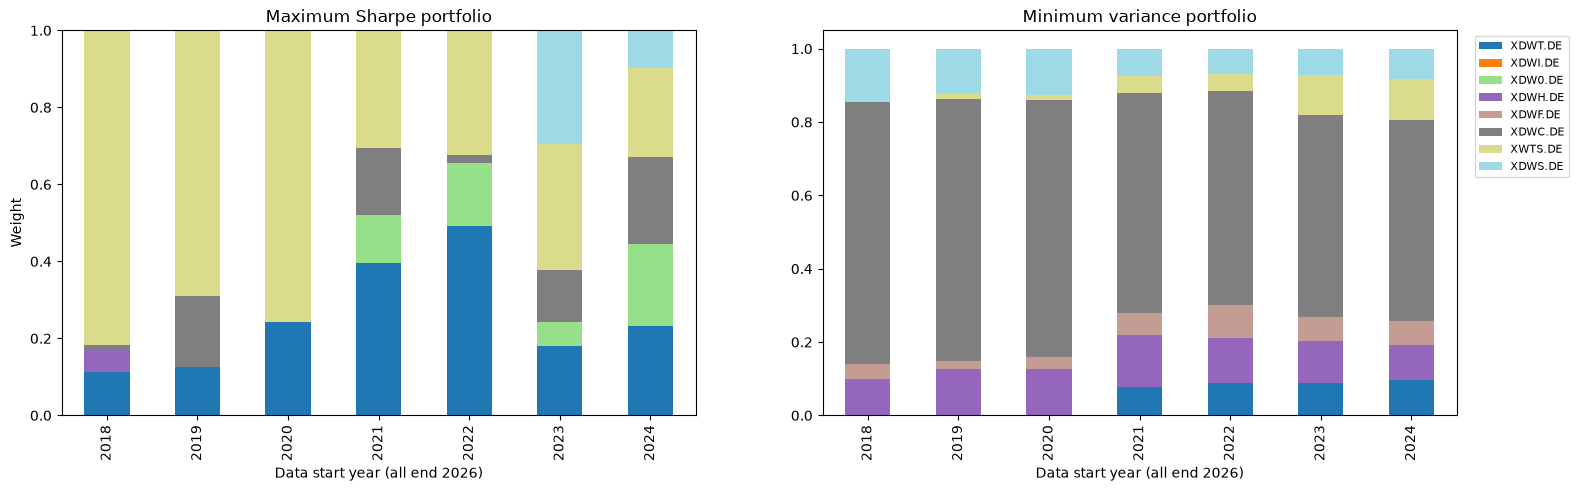

In [42]:
w_ms = pd.DataFrame({y: wms[y].x for y in years_sorted}, index=symbols).T
w_mv = pd.DataFrame({y: wmv[y].x for y in years_sorted}, index=symbols).T

plt.figure(figsize=(18, 5))

plt.subplot(1, 2, 1)
w_ms.plot(kind='bar', stacked=True, colormap='tab20', ax=plt.gca(), legend=False)
plt.title('Maximum Sharpe portfolio')
plt.xlabel('Data start year (all end 2026)')
plt.ylabel('Weight')

plt.subplot(1, 2, 2)
w_mv.plot(kind='bar', stacked=True, colormap='tab20', ax=plt.gca())
plt.title('Minimum variance portfolio')
plt.xlabel('Data start year (all end 2026)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

plt.show()